# Point-supervised remote-sensing segmentation: reviewer walkthrough

**Evidence status:** reconstructed implementation; real-data training and controlled experiments are blocked. This notebook executes small software demonstrations and inspects saved artifacts. It never starts campaign training or accesses test data. Toy tensors and geometric plots are explicitly synthetic.

The original assessment asks for Partial CE, integration on real remote-sensing data, and factor experiments with a report. Read `report/technical_report.pdf`, `report/evidence_inventory.json`, and `report/reviewer_audit.md` alongside this notebook. Missing outputs are shown as missing, not filled with historical smoke values.

## 1. Imports and setup

In [1]:
from pathlib import Path
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.config import load_config, resolve_path
from src.losses import PartialCrossEntropyLoss
from src.point_sampling import sample_points
from src.model import build_model
from src.evaluate import validate_saved_metrics
%matplotlib inline

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
cfg = load_config(ROOT / "configs/cpu_paired.yaml")
torch.set_num_threads(4)
section_status = {"setup": "verified"}
print(f"Python project: {ROOT.name}; Torch {torch.__version__}; CUDA {torch.cuda.is_available()}")
print("Campaign training disabled in this walkthrough.")

/workspace/remote-sensing-point-segmentation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python project: remote-sensing-point-segmentation; Torch 2.14.0+cpu; CUDA False
Campaign training disabled in this walkthrough.


## 2. Dataset sample

The intended source is LandCover.ai v1: RGB aerial images and labels 0 background, 1 building, 2 woodland, 3 water, 4 road. Padding/unselected labels are 255. The data license is CC BY-NC-SA 4.0; imagery attribution is the Head Office of Geodesy and Cartography, Poland. Dataset facts are retained from the recovery checkpoint until official data can be inspected again.

This cell displays a real **training** tile only if its manifest and rasters exist. It does not substitute a generated image.

In [2]:
manifest = resolve_path(cfg, cfg["data"]["manifest"])
train_data = None
if manifest.exists():
    from src.dataset import SegmentationDataset
    train_data = SegmentationDataset(cfg, "train", "uniform_50", 17)
    sample = train_data.diagnostic_dense(0)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    ax[0].imshow(sample["rgb"].transpose(1, 2, 0)); ax[0].set_title("Real training RGB")
    ax[1].imshow(np.ma.masked_where(~sample["valid_mask"], sample["dense_target"]), vmin=0, vmax=4)
    ax[1].set_title("Dense reference: diagnostic only")
    for a in ax: a.axis("off")
    plt.show()
    section_status["dataset_sample"] = "available"
else:
    print("BLOCKED: official rasters and data/manifests/splits.json are absent.")
    section_status["dataset_sample"] = "blocked_missing_real_data"

BLOCKED: official rasters and data/manifests/splits.json are absent.


## 3. Sparse annotation visualization

Uniform and stratified sampling both use 50 points. Coordinates are fixed before augmentation and independent of semantic labels. The fallback below is a **synthetic geometric demonstration**, not an aerial image or a segmentation result. No sampled class labels are invented.

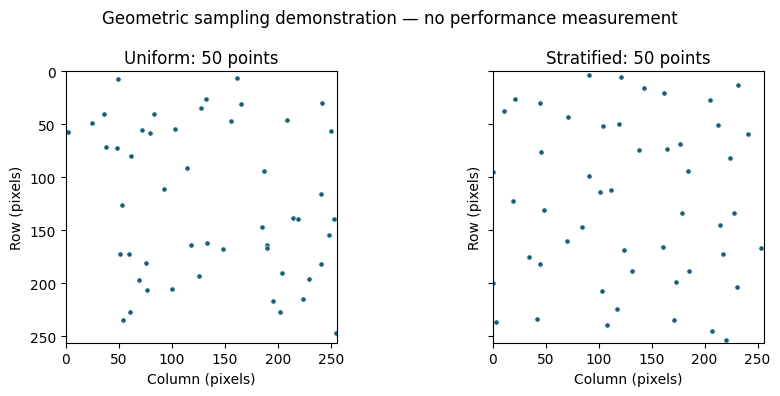

In [3]:
valid = sample["valid_mask"] if train_data is not None else np.ones((256, 256), dtype=bool)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, strategy in zip(axes, ["uniform", "stratified"]):
    points = sample_points(valid, 50, 17, strategy)
    yy, xx = np.nonzero(points)
    if train_data is not None:
        ax.imshow(sample["rgb"].transpose(1, 2, 0))
    ax.scatter(xx, yy, s=14, facecolor="#155e75", edgecolor="white", linewidth=.4)
    ax.set(xlim=(0, valid.shape[1]), ylim=(valid.shape[0], 0), xlabel="Column (pixels)",
           ylabel="Row (pixels)", title=f"{strategy.capitalize()}: {points.sum()} points")
    ax.set_aspect("equal")
fig.suptitle("Geometric sampling demonstration — no performance measurement")
fig.tight_layout(); plt.show()
section_status["sparse_visualization"] = "real_geometry" if train_data is not None else "synthetic_geometry_only"

## 4. Partial Cross-Entropy demonstration

For valid annotated pixels $M$, $N=|M|$ and class probability $p_\theta$, $L=-N^{-1}\sum_{i\in M}\log p_\theta(y_i\mid x_i)$. The implementation selects logits before arithmetic and averages over the batch's total selected count. Synthetic logits below verify equivalence with ordinary CE when fully labeled, zero direct gradient at unselected logits, and an autograd-connected empty loss. Empty training batches skip forward propagation and the optimizer.

In [4]:
generator = torch.Generator().manual_seed(17)
logits = torch.randn(2, 5, 8, 8, generator=generator, requires_grad=True)
labels = torch.randint(0, 5, (2, 8, 8), generator=generator)
loss_fn = PartialCrossEntropyLoss()
full = loss_fn(logits, labels, torch.ones_like(labels, dtype=torch.bool))
ordinary = torch.nn.functional.cross_entropy(logits, labels)
torch.testing.assert_close(full, ordinary)
point_mask = torch.zeros_like(labels, dtype=torch.bool)
point_mask[0, 1, 2] = True; point_mask[1, 3, 4] = True
sparse = torch.full_like(labels, 255); sparse[point_mask] = labels[point_mask]
loss = loss_fn(logits, sparse, point_mask); loss.backward()
assert torch.count_nonzero(logits.grad.permute(0, 2, 3, 1)[~point_mask]) == 0
empty = loss_fn(logits, sparse, torch.zeros_like(point_mask))
assert empty.item() == 0 and empty.requires_grad
print("PASS: full-label equivalence, zero unselected direct gradients, connected empty loss.")
print("Synthetic numerical demonstration only; no segmentation quality measured.")
section_status["partial_ce"] = "verified"

PASS: full-label equivalence, zero unselected direct gradients, connected empty loss.
Synthetic numerical demonstration only; no segmentation quality measured.


## 5. Segmentation architecture

SMP U-Net, ResNet-18 encoder, decoder widths 256/128/64/32/16, RGB input, five raw logits. Inputs are padded to multiples of 32 and cropped back. This check uses **untrained weights**, performs no downloads and does not demonstrate learned predictions. Campaigns request verified ImageNet initialization; the cached initialization hash is recorded separately.

In [5]:
model = build_model(cfg, initialize=False).eval()
with torch.inference_mode():
    shape = list(model(torch.zeros(1, 3, 65, 97)).shape)
parameters = sum(p.numel() for p in model.parameters())
assert shape == [1, 5, 65, 97] and parameters == 14_328_789
print({"parameters": parameters, "padded_forward_output": shape, "trained": False})
init = json.loads((ROOT / "results/verification/reconstructed_initialization.json").read_text())
print({"recorded_initialization_check": init["status"], "sha256": init["encoder_weight_sha256"]})
section_status["architecture"] = "synthetic_forward_verified"
del model

{'parameters': 14328789, 'padded_forward_output': [1, 5, 65, 97], 'trained': False}
{'recorded_initialization_check': 'passed', 'sha256': 'f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec'}


## 6. Training setup

The candidate CPU campaign controls all factors except point budget or strategy. A2 is reused as B1. Three paired seeds are planned, but feasibility requires real-data timing. These are planned settings, not executed runs. Training is intentionally an explicit CLI operation after preflight.

In [6]:
from experiments.run_experiments import plan
jobs = plan(cfg)
print(json.dumps({"profile": cfg["profile"], "training": cfg["training"],
                  "tile_caps": cfg["data"]["tile_caps"], "seeds": cfg["experiment"]["seeds"],
                  "conditions": cfg["experiment"]["conditions"], "planned_runs": len(jobs)}, indent=2))
for k in (10, 50, 200):
    print(f"Nominal full-tile annotation fraction, K={k}: {100*k/(256*256):.8f}%")
print("Actual pooled fractions require annotations.json from real training subsets.")
section_status["training_setup"] = "planned_only"

{
  "profile": "cpu_paired",
  "training": {
    "epochs": 10,
    "batch_size": 2,
    "num_workers": 0,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "scheduler": "cosine",
    "min_lr": 1e-06,
    "early_stopping_patience": null,
    "device": "cpu",
    "amp": false,
    "threads": 4
  },
  "tile_caps": {
    "train": 128,
    "val": 32,
    "test": 32
  },
  "seeds": [
    17,
    29,
    43
  ],
  "conditions": [
    "uniform_10",
    "uniform_50",
    "uniform_200",
    "stratified_50"
  ],
  "planned_runs": 12
}
Nominal full-tile annotation fraction, K=10: 0.01525879%
Nominal full-tile annotation fraction, K=50: 0.07629395%
Nominal full-tile annotation fraction, K=200: 0.30517578%
Actual pooled fractions require annotations.json from real training subsets.


## 7. Checkpoint inspection

A saved checkpoint may be loaded without downloading encoder initialization. This walkthrough inspects the first completed campaign checkpoint only when it exists; it does not launch expensive training. The package contains no trained checkpoint because none was recovered or produced in this environment.

In [7]:
completed = []
for job in jobs:
    run_path = Path(job["directory"]) / "run.json"
    if run_path.exists() and json.loads(run_path.read_text())["status"] == "completed":
        completed.append(job)
if completed:
    from src.checkpoint import load_checkpoint
    checkpoint = Path(completed[0]["directory"]) / "checkpoints/best.pt"
    state = load_checkpoint(checkpoint)
    restored = build_model(state["config"], initialize=False)
    restored.load_state_dict(state["model"])
    print({"checkpoint": str(checkpoint), "epoch": state["epoch"], "condition": state["condition"]})
    section_status["checkpoint"] = "loaded"
    del restored, state
else:
    print("BLOCKED: no completed real-data campaign checkpoint exists.")
    section_status["checkpoint"] = "blocked_missing_checkpoint"

BLOCKED: no completed real-data campaign checkpoint exists.


## 8. Evaluation evidence

Evaluation pools one confusion matrix, with ground-truth rows and prediction columns, includes background and excludes padding. Classes absent from both sides are omitted from macro scores; false-positive-only classes score zero. Saved scores are recomputed from the matrix below when available. No test inference occurs here.

In [8]:
if completed:
    saved = json.loads((Path(completed[0]["directory"]) / "best_validation.json").read_text())
    validate_saved_metrics(saved["metrics"])
    print(json.dumps(saved, indent=2))
    section_status["evaluation"] = "saved_validation_metrics_checked"
else:
    print("BLOCKED: no real-data confusion matrix or validation/test metrics exist.")
    section_status["evaluation"] = "blocked_missing_metrics"

BLOCKED: no real-data confusion matrix or validation/test metrics exist.


## 9. Experimental result visualization

Results are read from the actual campaign export. Missing runs receive no invented score, error bar or prediction. When results exist, this view plots individual seed measurements; full figures and editable chart data are generated by `experiments.analyze_results`.

In [9]:
result_path = ROOT / cfg["experiment"]["output_root"] / "results.json"
rows = json.loads(result_path.read_text()) if result_path.exists() else []
status_path = result_path.with_name("run_status.json")
statuses = json.loads(status_path.read_text()) if status_path.exists() else []
print({"measured_rows": len(rows), "run_status_counts": {
    s: sum(r["status"] == s for r in statuses) for s in sorted({r["status"] for r in statuses})}})
if rows:
    val_rows = [r for r in rows if r["split"] == "val"]
    fig, ax = plt.subplots(figsize=(8, 4))
    for condition in cfg["experiment"]["conditions"]:
        values = [r["miou"] for r in val_rows if r["condition"] == condition]
        ax.scatter([condition] * len(values), values, label=condition)
    ax.set(ylabel="Validation mIoU (0–1)", title="Recorded per-seed validation results")
    plt.xticks(rotation=20); fig.tight_layout(); plt.show()
    section_status["experimental_results"] = "saved_rows_displayed"
else:
    display(Markdown("**No empirical performance figure can be produced: all required runs are blocked.**"))
    section_status["experimental_results"] = "blocked_zero_completed_runs"

{'measured_rows': 0, 'run_status_counts': {'blocked_prerequisites': 12}}


**No empirical performance figure can be produced: all required runs are blocked.**

## 10. Key observations and next steps

The software demonstrations establish mathematical and interface behavior on synthetic inputs. They do not establish segmentation quality on LandCover.ai. Annotation-density and stratification hypotheses remain untested. Real-data class support, rare-class errors, seed variance and practical annotation needs are unmeasured.

Restore official data access; verify archive, geographic partitions and full held-out masks; run a real-data smoke with exact checkpoint reload; then execute the controlled campaign. Freeze checkpoints before final test inference. Replace blocked report sections only with verified saved measurements. Simulated points also do not measure human annotation time, ambiguity or selection behavior.

In [10]:
suite = json.loads((ROOT / "results/verification/current_suite.json").read_text())
print({k: suite[k] for k in ("status", "passed", "skipped", "failures", "errors")})
section_status["observations"] = "limitations_documented"
print("NOTEBOOK_SECTION_STATUS=" + json.dumps(section_status, sort_keys=True))

{'status': 'passed', 'passed': 131, 'skipped': 1, 'failures': 0, 'errors': 0}
NOTEBOOK_SECTION_STATUS={"architecture": "synthetic_forward_verified", "checkpoint": "blocked_missing_checkpoint", "dataset_sample": "blocked_missing_real_data", "evaluation": "blocked_missing_metrics", "experimental_results": "blocked_zero_completed_runs", "observations": "limitations_documented", "partial_ce": "verified", "setup": "verified", "sparse_visualization": "synthetic_geometry_only", "training_setup": "planned_only"}
